## POSTER - ECONOMETRIA 2 - Precio del Oro por Gramo Fino 

## Installacion de paquetes requeridos

In [2]:
%pip install numpy pandas matplotlib seaborn statsmodels   
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings
warnings.filterwarnings('ignore')


Note: you may need to restart the kernel to use updated packages.


## Limpieza de datos

In [ ]:
Directorio = Path("")
Ruta = Directorio / "Base de datos - Poster.csv"

df = pd.read_csv(Ruta, sep=";")
df["fecha"] = pd.to_datetime(df["fecha"], format = "%d/%m/%Y", errors = "coerce")
df = df.dropna().set_index("fecha")
df["Precio Oro regalías"] = df["Precio Oro regalías"].str.replace(",", ".", regex=False).astype(float)

df.info()
df.describe()

<class 'pandas.DataFrame'>
DatetimeIndex: 340 entries, 1998-07-01 to 2026-10-01
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Precio Oro regalías  340 non-null    float64
dtypes: float64(1)
memory usage: 5.3 KB


,Precio Oro regalías
count,340.000000
mean,99979.912441
std,97027.993368
min,12044.330000
25%,28235.965000
50%,68499.385000
75%,128791.297500
max,474134.790000


Grafico de la serie

## METODOLOGIA BOX-JENKINS

#### Serie de tiempo  

In [36]:
serie = df["Precio Oro regalías"]

<Axes: title={'center': 'Precio del Oro en Colombia'}, xlabel='fecha'>

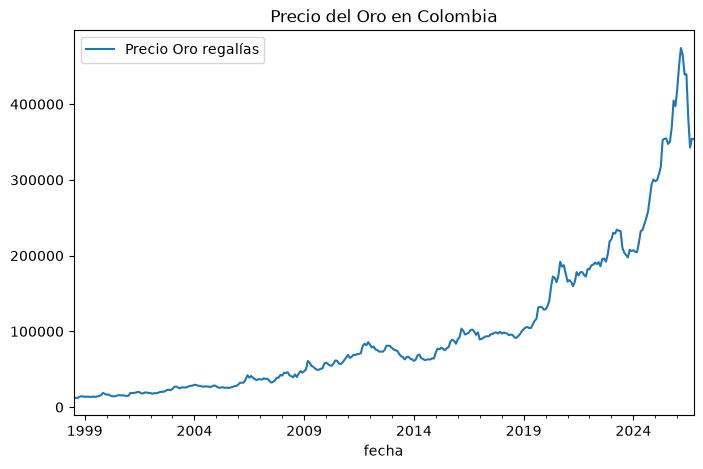

In [59]:
df.plot(figsize=(8, 5), title="Precio del Oro en Colombia")

#### Prueba Dickey Fuller Aumentada

In [ ]:
#H0: La serie tiene raíz unitaria (no estacionaria)
#H1: La serie no tiene raíz unitaria (es estacionaria)

prueba_df = adfuller(serie, regression="c")
print("\n Prueba de Dickey-Fuller aumentada (ADF) con tendencia y constante:")
print(f'Estadístico de prueba: {prueba_df[0]:.4f}')
print(f'Valor p: {prueba_df[1]:.4f}')


 Prueba de Dickey-Fuller aumentada (ADF) con tendencia y constante:
Estadístico de prueba: 1.9918
Valor p: 0.9987


#### Aplicar diferencias para volver estacionaria la serie, y volver a hacer prueba DF

In [53]:
serie_diferenciada = serie.diff().dropna()

prueba_df_diferenciada = adfuller(serie_diferenciada, regression="c")

print("\n Prueba de Dickey-Fuller aumentada (ADF) con tendencia y constante para la serie diferenciada:")
print(f"Estadistico de prueba:{prueba_df_diferenciada[0]}")
print(f"Valor-P:{prueba_df_diferenciada[1]}")


 Prueba de Dickey-Fuller aumentada (ADF) con tendencia y constante para la serie diferenciada:
Estadistico de prueba:-13.016092959741556
Valor-P:2.5092827596801196e-24


#### FAC y FACP

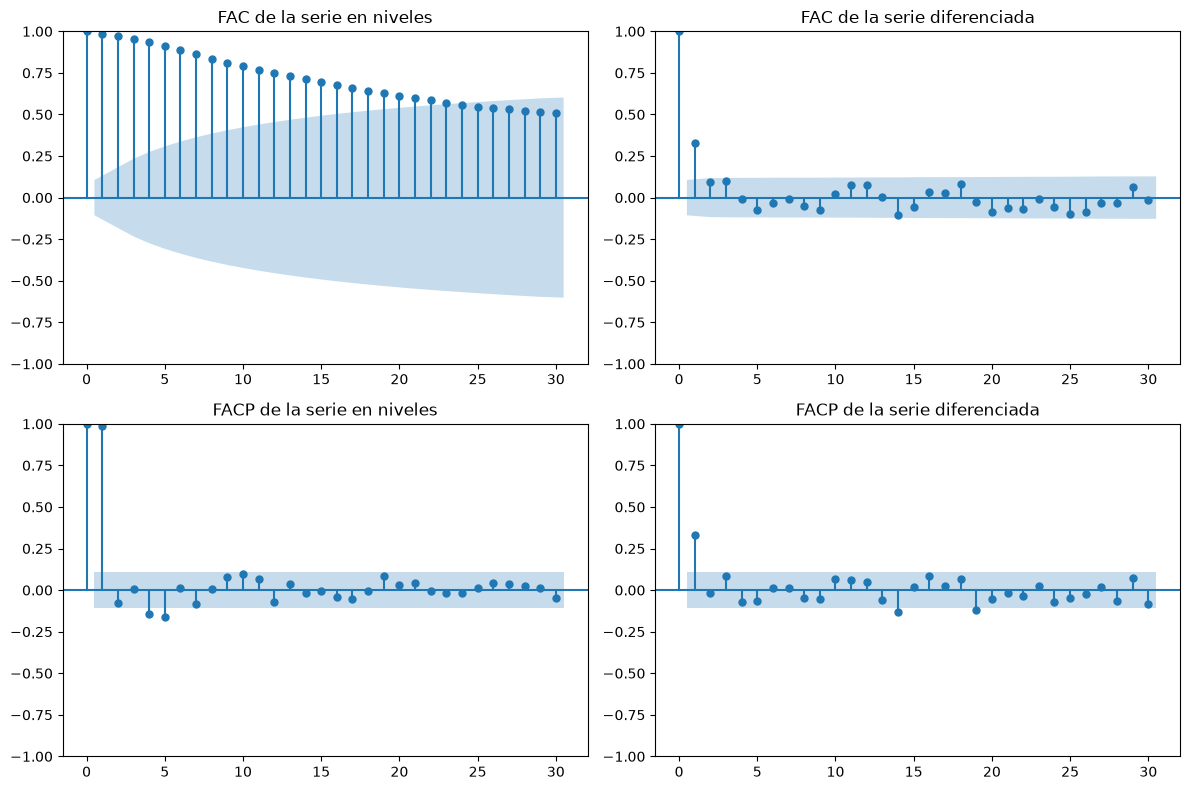

In [54]:
fig , axes = plt.subplots(2,2, figsize=(12,8))

plot_acf(serie, ax=axes[0,0], lags=30, title="FAC de la serie en niveles")
plot_pacf(serie, ax=axes[1,0], lags=30, title="FACP de la serie en niveles")

plot_acf(serie_diferenciada, ax=axes[0,1], lags=30, title="FAC de la serie diferenciada")
plot_pacf(serie_diferenciada, ax=axes[1,1], lags=30, title="FACP de la serie diferenciada")

plt.tight_layout()
plt.show()

### Modelo ARIMA

In [55]:
modelos_candidatos = [(1,1,0), (0,1,1), (1,1,1), (2,1,0), (0,1,2), (2,1,2)]
resultados = []


for order in modelos_candidatos:
    modelo = SARIMAX(serie, order=order, trend="c")
    resultado = modelo.fit(disp=False)
    resultados.append({
        "Modelo": f"ARIMA{order}",
        "AIC": resultado.aic,
        "BIC": resultado.bic,
        "log-likelihood": resultado.llf
    })

resultados_df = pd.DataFrame(resultados)
resultados_df = resultados_df.sort_values(by="AIC").reset_index(drop=True)

print("\nResultados de los modelos ARIMA:")
print(resultados_df)


Resultados de los modelos ARIMA:
           Modelo          AIC          BIC  log-likelihood
0  ARIMA(1, 1, 0)  6934.802383  6946.280383    -3464.401192
1  ARIMA(0, 1, 1)  6935.447717  6946.925717    -3464.723858
2  ARIMA(1, 1, 1)  6936.573064  6951.877064    -3464.286532
3  ARIMA(2, 1, 0)  6936.677041  6951.981041    -3464.338520
4  ARIMA(0, 1, 2)  6937.208555  6952.512555    -3464.604278
5  ARIMA(2, 1, 2)  6938.439259  6961.395260    -3463.219629
